In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.diagnostic import het_breuschpagan

# Cargar el dataset
df = pd.read_excel('dataset_Ventas.xlsx')

print('--- PRIMERAS FILAS ---')
print(df.head())

print('\n--- ESTADÍSTICOS DESCRIPTIVOS POR METODOLOGÍA ---')
print(
    df.groupby('Metodo')['Puntaje'].agg(
        ['count', 'mean', 'median', 'std', 'min', 'max']
    )
)

# Ajuste del modelo de regresión lineal (con variables dummy automáticas)
modelo = ols('Puntaje ~ C(Metodo)', data=df).fit()
print('\n--- RESUMEN DEL MODELO OLS ---')
print(modelo.summary())

# Validación de Supuestos
# Homocedasticidad (Breusch-Pagan)
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
print(f'\nTest de Breusch-Pagan (Homocedasticidad) p-value: {bp_test[1]:.4f}')

# Normalidad de residuos (Shapiro-Wilk)
shapiro_test = stats.shapiro(modelo.resid)
print(f'Test de Shapiro-Wilk (Normalidad) p-value: {shapiro_test.pvalue:.4f}')

# Evaluación Predictiva (Train/Test Split 80/20)
df_encoded = pd.get_dummies(df, columns=['Metodo'], drop_first=True, dtype=int)
X = df_encoded[['Metodo_Gamificado', 'Metodo_Tradicional']]
y = df_encoded['Puntaje']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print('\n--- EVALUACIÓN PREDICTIVA (CONJUNTO DE PRUEBA) ---')
print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')

--- PRIMERAS FILAS ---
   ID       Metodo    Puntaje
0   1  Tradicional  69.197622
1   2  Tradicional  70.849113
2   3  Tradicional  79.793542
3   4  Tradicional  72.352542
4   5  Tradicional  72.646439

--- ESTADÍSTICOS DESCRIPTIVOS POR METODOLOGÍA ---
             count       mean     median       std        min        max
Metodo                                                                  
Flipped         30  78.891692  78.238269  4.175640  70.256236  88.844780
Gamificado      30  84.122102  84.146921  4.348969  72.454156  94.250423
Tradicional     30  71.764481  71.631334  4.905154  62.166914  80.934566

--- RESUMEN DEL MODELO OLS ---
                            OLS Regression Results                            
Dep. Variable:                Puntaje   R-squared:                       0.569
Model:                            OLS   Adj. R-squared:                  0.559
Method:                 Least Squares   F-statistic:                     57.32
Date:                Sun, 08 Nov 

/tmp/ipykernel_766/1657748634.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


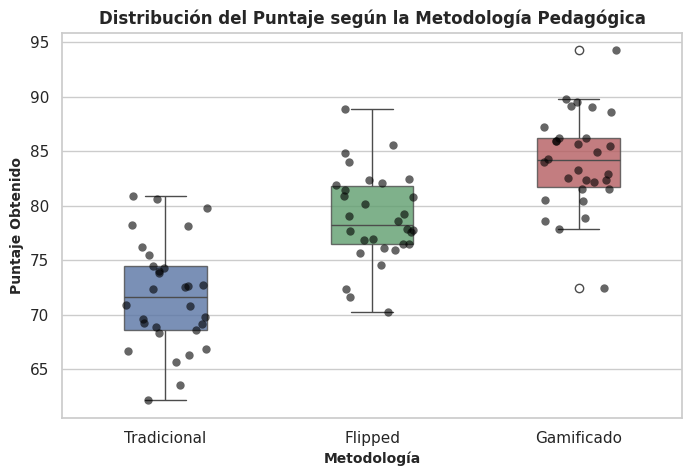

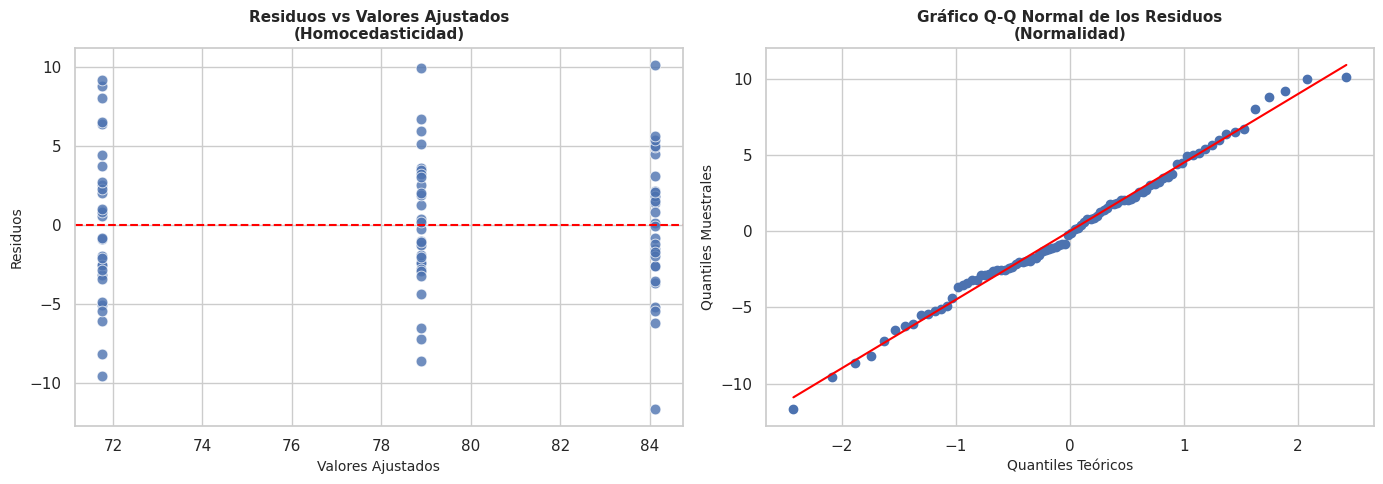

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
#Estilo
sns.set_theme(style='whitegrid')

# Distribución del Puntaje por Metodología (Boxplot + Puntos)
plt.figure(figsize=(8, 5))
sns.boxplot(
    x='Metodo',
    y='Puntaje',
    data=df,
    palette=['#4C72B0', '#55A868', '#C44E52'],
    width=0.4,
    boxprops=dict(alpha=0.8),
)
sns.stripplot(x='Metodo', y='Puntaje', data=df, color='black', alpha=0.6, jitter=0.2, size=6)

plt.title('Distribución del Puntaje según la Metodología Pedagógica', fontsize=12, fontweight='bold')
plt.xlabel('Metodología', fontsize=10, fontweight='bold')
plt.ylabel('Puntaje Obtenido', fontsize=10, fontweight='bold')

plt.savefig('boxplot_metodologia.png', dpi=300, bbox_inches='tight')

plt.show()

# Diagnóstico de Supuestos (Residuos y Q-Q Normal)

# Ajustar el modelo OLS necesario para los residuos
modelo = smf.ols('Puntaje ~ C(Metodo)', data=df).fit()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuos vs Valores Ajustados (Homocedasticidad y Linealidad)
sns.scatterplot(x=modelo.fittedvalues, y=modelo.resid, ax=axes[0], color='#4C72B0', alpha=0.8, s=60)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuos vs Valores Ajustados\n(Homocedasticidad)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Valores Ajustados', fontsize=10)
axes[0].set_ylabel('Residuos', fontsize=10)

# B. Gráfico Q-Q Normal de los Residuos (Normalidad)
stats.probplot(modelo.resid, dist='norm', plot=axes[1])
axes[1].get_lines()[0].set_markerfacecolor('#4C72B0')
axes[1].get_lines()[0].set_markeredgecolor('#4C72B0')
axes[1].get_lines()[1].set_color('red')
axes[1].set_title('Gráfico Q-Q Normal de los Residuos\n(Normalidad)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Quantiles Teóricos', fontsize=10)
axes[1].set_ylabel('Quantiles Muestrales', fontsize=10)

plt.tight_layout()

plt.savefig('diagnostico_supuestos.png', dpi=300, bbox_inches='tight')

plt.show()